# 01 — Data Understanding, Schema Audit & Cohort Selection Bias (`data-v1`)
This notebook audits the raw release files (`vm_cpu_readings.csv.gz` and `vm_metadata.csv.gz`), verifies panel completeness and physical CPU bounds (`0 <= min <= avg <= max <= 100`), quantifies virtual-core capacity (`28,396` vCores), and proves why `active_vm_count` is deterministically `10,000` across all `134` timestamps (`0..39,900s`).

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from cwfc.io import load_cpu_readings, load_vm_metadata
from cwfc.quality import compute_data_quality_report
from cwfc.policy import compute_fleet_core_capacity

DATA_DIR = Path('../challenge_data')
readings = load_cpu_readings(DATA_DIR)
metadata = load_vm_metadata(DATA_DIR)
dq = compute_data_quality_report(readings, metadata)
print('=== Automated Data Quality Summary ===')
print(json.dumps({k: dq[k] for k in [
    'total_rows', 'unique_vms', 'unique_timestamps', 'timestamp_min', 'timestamp_max',
    'is_regular_cadence', 'is_balanced_panel', 'duplicate_vm_timestamp_pairs',
    'missing_values_cpu', 'ordering_violations', 'created_timestamp_min',
    'created_timestamp_max', 'deleted_timestamp_min', 'deleted_timestamp_max'
]}, indent=2))

=== Automated Data Quality Summary ===
{
  "total_rows": 1340000,
  "unique_vms": 10000,
  "unique_timestamps": 134,
  "timestamp_min": 0,
  "timestamp_max": 39900,
  "is_regular_cadence": true,
  "is_balanced_panel": true,
  "duplicate_vm_timestamp_pairs": 0,
  "missing_values_cpu": {
    "min_cpu": 0,
    "avg_cpu": 0,
    "max_cpu": 0
  },
  "ordering_violations": {
    "min_gt_avg": 0,
    "avg_gt_max": 0,
    "out_of_0_100_range": 0
  },
  "created_timestamp_min": 0,
  "created_timestamp_max": 0,
  "deleted_timestamp_min": 40500,
  "deleted_timestamp_max": 2591400
}


In [2]:
# Cross-sectional CPU distribution summary across all 1,340,000 rows
dist_df = pd.DataFrame(dq['cpu_bounds']).T[['min', 'p25', 'median', 'mean', 'p75', 'p95', 'max']]
dist_df['burst_spread_mean'] = [np.nan, np.nan, float((readings['max_cpu'] - readings['min_cpu']).mean())]
display(dist_df.round(4))

,min,p25,median,mean,p75,p95,max,burst_spread_mean
min_cpu,0.0000,1.4880,3.2280,6.1565,5.3311,22.8259,99.2816,NaN
avg_cpu,0.0072,2.4771,5.1051,9.3881,9.6167,37.1329,99.4880,NaN
max_cpu,0.0181,4.4176,9.1242,18.3483,23.6242,65.6387,99.7029,12.1918


In [3]:
# Metadata stratification & cohort survival analysis (why active_vm_count == 10,000)
cat_summary = metadata.groupby('vm_category', dropna=False).agg(
    vm_count=('vm_id', 'count'),
    first_deleted_s=('timestamp_vm_deleted', 'min'),
    median_deleted_s=('timestamp_vm_deleted', 'median'),
).sort_values('vm_count', ascending=False)
core_summary = metadata.groupby('virtual_core_bucket', dropna=False).agg(
    vm_count=('vm_id', 'count'),
    mem_modes=('memory_gb_bucket', lambda s: s.value_counts().index[0]),
)
print('=== VM Metadata by Category ===')
display(cat_summary)
print('=== VM Metadata by Virtual Core Bucket ===')
display(core_summary)

=== VM Metadata by Category ===


,vm_count,first_deleted_s,median_deleted_s
vm_category,,,
Delay-insensitive,6180,603000,2591400.0
Interactive,3091,606600,2591400.0
Unknown,729,40500,314100.0


=== VM Metadata by Virtual Core Bucket ===


,vm_count,mem_modes
virtual_core_bucket,,
2,7534,2
24,62,64
4,1908,8
8,486,32
>24,10,>64


Total Provisioned Fleet vCores: 28,396
Full-Trace Core-Weighted Mean CPU: 9.291% (Holdout: 9.226%)
Mean Demanded vCores (5-min avg): 2638.3 vCores | Mean 5-min Peak Demanded vCores: 5310.3 vCores (Peak/Avg = 2.01x)


,timestamp,active_vm_count,total_provisioned_cores,core_weighted_cpu_utilization,demanded_cores_avg,demanded_cores_peak,peak_to_avg_ratio
count,134.000,134.0,134.0,134.000,134.000,134.000,134.000
mean,19950.000,10000.0,28396.0,9.291,2638.333,5310.332,2.013
std,11647.961,0.0,0.0,0.185,52.588,119.281,0.022
min,0.000,10000.0,28396.0,8.867,2517.808,5074.416,1.948
25%,9975.000,10000.0,28396.0,9.149,2597.941,5224.970,2.000
50%,19950.000,10000.0,28396.0,9.269,2631.948,5295.461,2.014
75%,29925.000,10000.0,28396.0,9.442,2681.062,5386.425,2.029
max,39900.000,10000.0,28396.0,9.693,2752.514,5630.045,2.074


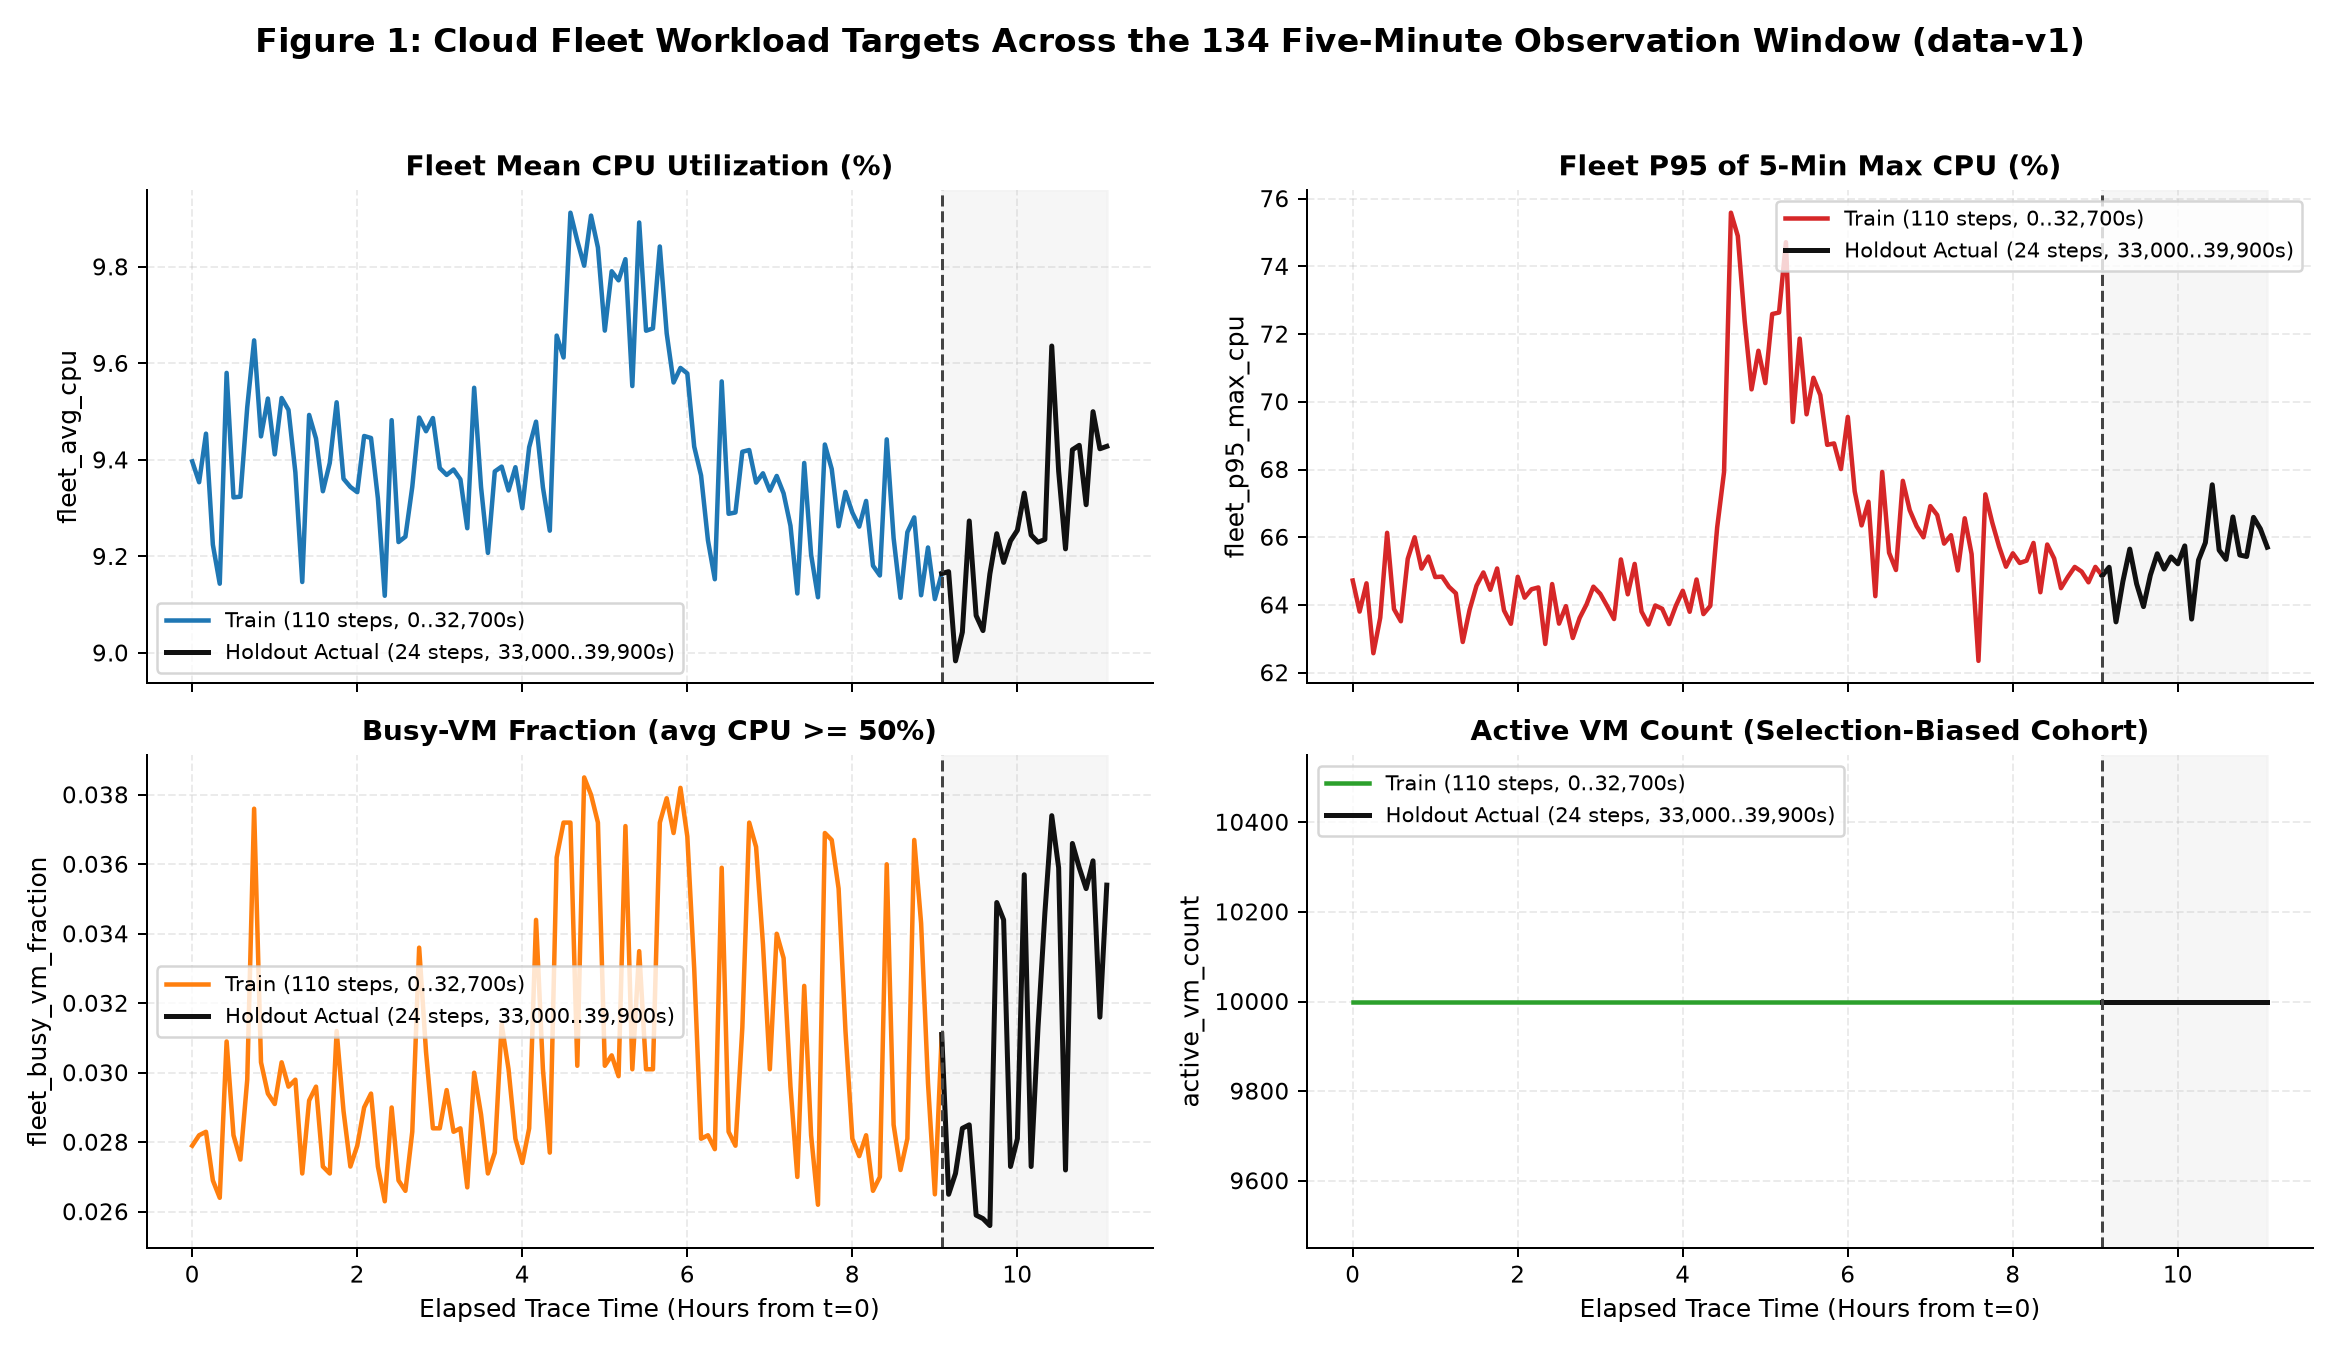

In [4]:
# Provisioned vCore capacity & core-weighted vs unweighted utilization
cap_df = compute_fleet_core_capacity(readings, metadata)
print(f"Total Provisioned Fleet vCores: {int(cap_df['total_provisioned_cores'].iloc[0]):,}")
print(f"Full-Trace Core-Weighted Mean CPU: {cap_df['core_weighted_cpu_utilization'].mean():.3f}% "
      f"(Holdout: {cap_df.iloc[110:]['core_weighted_cpu_utilization'].mean():.3f}%)")
print(f"Mean Demanded vCores (5-min avg): {cap_df['demanded_cores_avg'].mean():.1f} vCores | "
      f"Mean 5-min Peak Demanded vCores: {cap_df['demanded_cores_peak'].mean():.1f} vCores "
      f"(Peak/Avg = {cap_df['peak_to_avg_ratio'].mean():.2f}x)")
display(cap_df.describe().round(3))
display(Image(filename='../reports/figures/fig1_fleet_overview.png'))